# Búsqueda exhaustiva: los LMS3TG son el grafo modelo $G^*_{n,m}$

Para cada clase $\mathcal{T}_{n,m}$ con $b(n,m)\ge 2$ este notebook:

1. enumera todos los grafos 3-terminales no isomorfos;
2. calcula su tupla $F=(F_1,\dots,F_m)$;
3. se queda con los de tupla lexicográficamente máxima (los localmente más separables cerca de $p=1$);
4. construye $G^*_{n,m}$ según la Definición del grafo modelo y comprueba que tiene esa tupla, que los ganadores son exactamente su clase y que el índice de decisión es el predicho.

## 1. Separabilidad: la tupla $F$

In [1]:
from itertools import combinations, product


def _suma(a, b):
    if len(a) < len(b):
        a, b = b, a
    r = list(a)
    for i, c in enumerate(b):
        r[i] += c
    return r


def _producto(a, b):
    r = [0] * (len(a) + len(b) - 1)
    for i, x in enumerate(a):
        if x:
            for j, y in enumerate(b):
                if y:
                    r[i + j] += x * y
    return r


class TablaConexos:
    # C(S): coeficiente j = # subgrafos generadores conexos de G[S] con j aristas
    def __init__(self, G):
        self.vertices = list(G.vertices(sort=True))
        self.indice = {v: i for i, v in enumerate(self.vertices)}
        self.ady = [0] * len(self.vertices)
        for u, v in G.edges(labels=False, sort=False):
            iu, iv = self.indice[u], self.indice[v]
            self.ady[iu] |= 1 << iv
            self.ady[iv] |= 1 << iu
        self.binom = [[binomial(e, j) for j in range(e + 1)] for e in range(G.size() + 1)]
        self._C, self._e = {}, {}

    def aristas(self, S):
        if S not in self._e:
            total, T = 0, S
            while T:
                v = (T & -T).bit_length() - 1
                total += bin(self.ady[v] & S).count("1")
                T &= T - 1
            self._e[S] = total // 2
        return self._e[S]

    def todos(self, S):
        return self.binom[self.aristas(S)]

    def C(self, S):
        if S in self._C:
            return self._C[S]
        if S & (S - 1) == 0:
            res = [1]
        else:
            v0 = S & -S
            resto = S - v0
            res = list(self.todos(S))
            U = (resto - 1) & resto
            while True:
                T = v0 | U
                if T != S:
                    res = _suma(res, [-c for c in _producto(self.C(T), self.todos(S - T))])
                if U == 0:
                    break
                U = (U - 1) & resto
        while len(res) > 1 and res[-1] == 0:
            res.pop()
        self._C[S] = res
        return res


def F_tupla(G, terminales, tabla=None):
    # (F_1, ..., F_m) de G con los terminales dados
    tabla = tabla or TablaConexos(G)
    n, m = G.order(), G.size()
    ts = [tabla.indice[t] for t in terminales]
    otros = [i for i in range(n) if i not in ts]
    K = [0]
    for asign in product(range(3), repeat=len(otros)):
        bloques = [1 << t for t in ts]
        for v, a in zip(otros, asign):
            bloques[a] |= 1 << v
        term = [1]
        for B in bloques:
            term = _producto(term, tabla.C(B))
            if not any(term):
                break
        K = _suma(K, term)
    F = [0] * (m + 1)
    for j, c in enumerate(K):          # j aristas conservadas = m - j borradas
        F[m - j] += c
    return tuple(F[1:])


def forma_canonica(G, terminales):
    # clave de isomorfismo de grafos 3-terminales (los terminales pueden permutarse)
    ts = list(terminales)
    resto = [v for v in G.vertices(sort=True) if v not in ts]
    can, cert = G.canonical_label(partition=[ts, resto] if resto else [ts], certificate=True)
    return (can.graph6_string(), tuple(sorted(cert[t] for t in ts)))


# control rapido: K_{1,3} con terminales en las hojas tiene F = (0, 3, 0)
print(F_tupla(Graph([(0, 1), (0, 2), (0, 3)]), [1, 2, 3]))

(0, 3, 0)


## 2. El grafo modelo $G^*_{n,m}$

In [2]:
def b_nm(n, m):
    # b(n,m) = max{b : m - b <= binom(n-b, 2)}, para n <= m <= binom(n,2)
    return max(b for b in range(n) if m - b <= binomial(n - b, 2))


def terna_justa(b):
    q, r = divmod(b, 3)
    return tuple(sorted([q + (1 if i < r else 0) for i in range(3)], reverse=True))


def globo(np_, mp_):
    lam = mp_ - binomial(np_ - 1, 2)
    B = graphs.CompleteGraph(np_ - 1)
    B.add_vertex(np_ - 1)
    for u in range(lam):
        B.add_edge(np_ - 1, u)
    return B, np_ - 1, lam


def theta(H, patas):
    # Theta(H; (u1,l1), (u2,l2), (u3,l3)): devuelve (grafo, terminales)
    G = H.copy(immutable=False)
    sig = max(G.vertices(sort=True)) + 1
    ts = []
    for u, l in patas:
        actual = u
        for _ in range(l):
            G.add_edge(actual, sig)
            actual, sig = sig, sig + 1
        ts.append(actual)
    return G, ts


def caso(n, m):
    b = b_nm(n, m)
    np_, mp_ = n - b, m - b
    lam = mp_ - binomial(np_ - 1, 2)
    l1, l2, l3 = terna_justa(b)
    if lam == np_ - 1:
        return "(a)"
    if lam == np_ - 2:
        return "(b)" if l2 == l3 else "(b')"
    return "(c)"


def modelo(n, m):
    b = b_nm(n, m)
    np_, mp_ = n - b, m - b
    B, z, lam = globo(np_, mp_)
    l1, l2, l3 = terna_justa(b)
    c = caso(n, m)
    if c == "(a)":
        return theta(B, [(0, l1), (1, l2), (2, l3)])
    p, q = z, np_ - 2
    if c == "(b)":
        return theta(B, [(0, l1), (p, l2), (q, l3)])
    if c == "(b')":
        return theta(B, [(p, l1), (p, l2), (q, l3)])
    return theta(B, [(lam, l1), (lam + 1, l2), (z, l3)])   # w1, w2 en W


def variantes_bprima(n, m):
    # caso (b') con b >= 5: nucleo sobre la pata corta (en su extremo o en el interior)
    b = b_nm(n, m)
    if caso(n, m) != "(b')" or b < 3:
        return []
    np_, mp_ = n - b, m - b
    B, z, lam = globo(np_, mp_)
    l1, l2, l3 = terna_justa(b)
    p, q = z, np_ - 2
    salida = []
    for d in range(1, l3 + 1):          # distancia del nucleo a la mediana
        G = B.copy(immutable=False)
        sig = max(G.vertices(sort=True)) + 1
        actual = q
        for _ in range(d):
            G.add_edge(actual, sig); actual, sig = sig, sig + 1
        mediana, ts = actual, []
        for l in (l1, l2):
            actual = mediana
            for _ in range(l):
                G.add_edge(actual, sig); actual, sig = sig, sig + 1
            ts.append(actual)
        actual = p
        for _ in range(l3 - d):
            G.add_edge(actual, sig); actual, sig = sig, sig + 1
        ts.append(actual)
        salida.append((G, ts))
    return salida


def indice_predicho(n, m):
    # Tabla del Teorema A
    b = b_nm(n, m)
    np_ = n - b
    lam = m - b - binomial(np_ - 1, 2)
    c = caso(n, m)
    if c == "(a)":
        return np_ if b >= 3 else 2 * np_ - 3
    if c == "(b)":
        return np_
    if c == "(b')":
        return np_ - 1
    return np_ - 1 if b >= 3 else lam + np_ - 2


G, ts = modelo(7, 10)
print("G*_{7,10}:", sorted(G.edges(labels=False)), "terminales", ts)
print("F =", F_tupla(G, ts))

G*_{7,10}: [(0, 1), (0, 2), (0, 3), (0, 4), (1, 2), (1, 3), (1, 4), (2, 3), (2, 5), (3, 6)] terminales [5, 6, 4]
F = (0, 1, 10, 41, 97, 125, 0, 0, 0, 0)


## 3. Búsqueda exhaustiva en $\mathcal{T}_{n,m}$

In [3]:
def ganadores(n, m):
    # devuelve (tupla maxima, lista de ganadores no isomorfos, segunda mejor tupla, #candidatos)
    mejor, segunda, lista, total = None, None, [], 0
    for G in graphs.nauty_geng(f"{n} {m}:{m} -c"):
        tabla = TablaConexos(G)
        vistos = set()
        for ts in combinations(G.vertices(sort=True), 3):
            clave = forma_canonica(G, ts)
            if clave in vistos:
                continue
            vistos.add(clave)
            total += 1
            t = F_tupla(G, ts, tabla)
            if mejor is None or t > mejor:
                if mejor is not None:
                    segunda = mejor
                mejor, lista = t, [(G, ts)]
            elif t == mejor:
                lista.append((G, ts))
            elif segunda is None or t > segunda:
                segunda = t
    return mejor, lista, segunda, total


def primer_indice_distinto(a, b):
    return next((i + 1 for i, (x, y) in enumerate(zip(a, b)) if x != y), None)

## 4. Verificación del Teorema A

Para cada $(n,m)$ con $n\le m\le\binom{n-2}{2}+2$ (es decir, $b(n,m)\ge2$) se comprueba:

- la tupla máxima es la de $G^*_{n,m}$;
- cada ganador es isomorfo a $G^*_{n,m}$ o, en el caso (b'), a una de sus variantes;
- el índice de decisión observado (primer índice donde la mejor tupla le gana a la segunda) es el de la tabla del teorema.

Tiempos aproximados: $n\le7$ en menos de un minuto; $n=8$ del orden de media hora.

In [4]:
N_MAX = 7          # subir a 8 para la verificacion completa de n = 8

filas = []
for n in range(5, N_MAX + 1):
    for m in range(n, binomial(n - 2, 2) + 3):
        if b_nm(n, m) < 2:
            continue
        mejor, lista, segunda, total = ganadores(n, m)
        G, ts = modelo(n, m)
        modelos = [(G, ts)] + variantes_bprima(n, m)
        claves_modelo = {forma_canonica(H, t) for H, t in modelos}
        tupla_ok = all(F_tupla(H, t) == mejor for H, t in modelos)
        clases_ok = {forma_canonica(H, t) for H, t in lista} == claves_modelo
        d_obs = primer_indice_distinto(mejor, segunda)
        d_pred = indice_predicho(n, m)
        b = b_nm(n, m)
        np_ = n - b
        lam = m - b - binomial(np_ - 1, 2)
        filas.append((n, m, b, np_, lam, caso(n, m), terna_justa(b), total, len(lista),
                      tupla_ok, clases_ok, d_pred, d_obs))
        print(f"({n},{m}) b={b} n'={np_} lam'={lam} caso {caso(n, m):4} l={terna_justa(b)} "
              f"candidatos={total:6}  ganadores={len(lista)}  "
              f"tupla={'OK' if tupla_ok else 'FALLA'}  clases={'OK' if clases_ok else 'FALLA'}  "
              f"indice pred/obs = {d_pred}/{d_obs}", flush=True)

todo_ok = all(f[9] and f[10] and f[11] == f[12] for f in filas)
print()
print("Todas las clases coinciden con G*_{n,m} y con el indice predicho:" if todo_ok else "HAY DISCREPANCIAS", todo_ok)

(5,5) b=2 n'=3 lam'=2 caso (a)  l=(1, 1, 0) candidatos=    27  ganadores=1  tupla=OK  clases=OK  indice pred/obs = 3/3
(6,6) b=3 n'=3 lam'=2 caso (a)  l=(1, 1, 1) candidatos=   141  ganadores=1  tupla=OK  clases=OK  indice pred/obs = 3/3
(6,7) b=2 n'=4 lam'=2 caso (b') l=(1, 1, 0) candidatos=   215  ganadores=1  tupla=OK  clases=OK  indice pred/obs = 3/3
(6,8) b=2 n'=4 lam'=3 caso (a)  l=(1, 1, 0) candidatos=   238  ganadores=1  tupla=OK  clases=OK  indice pred/obs = 5/5
(7,7) b=4 n'=3 lam'=2 caso (a)  l=(2, 1, 1) candidatos=   663  ganadores=1  tupla=OK  clases=OK  indice pred/obs = 3/3
(7,8) b=3 n'=4 lam'=2 caso (b)  l=(1, 1, 1) candidatos=  1453  ganadores=1  tupla=OK  clases=OK  indice pred/obs = 4/4
(7,9) b=3 n'=4 lam'=3 caso (a)  l=(1, 1, 1) candidatos=  2345  ganadores=1  tupla=OK  clases=OK  indice pred/obs = 4/4
(7,10) b=2 n'=5 lam'=2 caso (c)  l=(1, 1, 0) candidatos=  2972  ganadores=1  tupla=OK  clases=OK  indice pred/obs = 5/5
(7,11) b=2 n'=5 lam'=3 caso (b') l=(1, 1, 0) ca

## 5. Un caso en detalle: dónde pierde el segundo mejor

tupla de G*  : (0, 1, 10, 41, 97, 125, 0, 0, 0, 0)
segunda mejor: (0, 1, 10, 41, 94, 110, 0, 0, 0, 0)
deciden en F_5: 97 contra 94


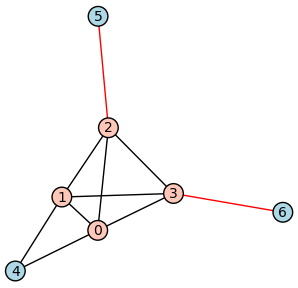

In [5]:
n, m = 7, 10
mejor, lista, segunda, total = ganadores(n, m)
d = primer_indice_distinto(mejor, segunda)
print("tupla de G*  :", mejor)
print("segunda mejor:", segunda)
print("deciden en F_%d: %d contra %d" % (d, mejor[d - 1], segunda[d - 1]))
G, ts = modelo(n, m)
G.plot(vertex_colors={"lightblue": ts}, edge_colors={"red": list(G.bridges(labels=False))}, figsize=4)

## 6. El caso (b'): una clase con grafos no isomorfos

En $(9,10)$ se tiene $b=5$, $\ell=(2,2,1)$ y núcleo $K_4-pq$. El teorema predice dos ganadores no isomorfos con la misma tupla: $G^*$ (dos patas largas en $p$, la corta en $q$) y el grafo con el núcleo en el extremo de la pata corta. Tarda unos minutos.

candidatos: 43990 | ganadores no isomorfos: 2 | tupla: (0, 8, 48, 96, 0, 0, 0, 0, 0, 0)
son exactamente G* y su variante: True


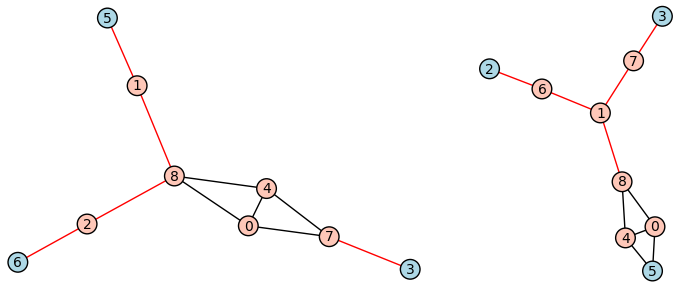

In [6]:
mejor, lista, segunda, total = ganadores(9, 10)
print("candidatos:", total, "| ganadores no isomorfos:", len(lista), "| tupla:", mejor)
modelos = [modelo(9, 10)] + variantes_bprima(9, 10)
print("son exactamente G* y su variante:",
      {forma_canonica(H, t) for H, t in lista} == {forma_canonica(H, t) for H, t in modelos})
graphics_array([H.plot(vertex_colors={"lightblue": t},
                       edge_colors={"red": list(H.bridges(labels=False))}) for H, t in lista]).show(figsize=[8, 3])

## 7. Fuera del teorema: $b(n,m)=1$

Con $m=\binom{n-1}{2}+1$ la plantilla $G^*_{n,m}$ (con terna $(1,0,0)$) no es el ganador: el LMS3TG no tiene puentes.

In [7]:
for n in (6, 7):
    m = binomial(n - 1, 2) + 1
    mejor, lista, segunda, total = ganadores(n, m)
    G, ts = modelo(n, m)
    H, th = lista[0]
    print(f"({n},{m}) b={b_nm(n, m)}: puentes del ganador = {len(list(H.bridges()))}, "
          f"F(ganador) = {mejor[:2*n-5]}..., F(G*) = {F_tupla(G, ts)[:2*n-5]}...")

(6,11) b=1: puentes del ganador = 0, F(ganador) = (0, 0, 0, 0, 2, 13, 47)..., F(G*) = (0, 0, 0, 0, 2, 12, 39)...
(7,16) b=1: puentes del ganador = 0, F(ganador) = (0, 0, 0, 0, 0, 2, 20, 91, 260)..., F(G*) = (0, 0, 0, 0, 0, 2, 20, 90, 251)...


## 8. Ejemplos del grafo modelo, como en la figura

Dibuja $G^*_{n,m}$ para un $(n,m)$ concreto de cada caso. Fila 1: $b\ge3$ con terna $(2,1,1)$, y $(2,2,1)$ en (b'): $(8,10)$, $(8,9)$, $(9,10)$, $(9,12)$. Fila 2: $b=2$ con terna $(1,1,0)$: $(7,12)$, $(7,11)$, $(7,10)$. El círculo punteado marca el núcleo, las aristas naranjas son los puentes y los círculos blancos son los terminales.

(a)  G*_{8,10}: b=4, nucleo B_{4,6}, l=(2, 1, 1), F=(0, 5, 30, 83, 115, 0, 0, 0, 0, 0)
(b)  G*_{8,9}: b=4, nucleo B_{4,5}, l=(2, 1, 1), F=(0, 5, 31, 69, 0, 0, 0, 0, 0)
(b') G*_{9,10}: b=5, nucleo B_{4,5}, l=(2, 2, 1), F=(0, 8, 48, 96, 0, 0, 0, 0, 0, 0)
(c)  G*_{9,12}: b=4, nucleo B_{5,8}, l=(2, 1, 1), F=(0, 5, 43, 158, 322, 340, 0, 0, 0, 0, 0, 0)
(a)  G*_{7,12}: b=2, nucleo B_{5,10}, l=(1, 1, 0), F=(0, 1, 10, 45, 124, 229, 297, 240, 0, 0, 0, 0)
(b') G*_{7,11}: b=2, nucleo B_{5,9}, l=(1, 1, 0), F=(0, 1, 9, 40, 106, 183, 175, 0, 0, 0, 0)
(c)  G*_{7,10}: b=2, nucleo B_{5,8}, l=(1, 1, 0), F=(0, 1, 10, 41, 97, 125, 0, 0, 0, 0)


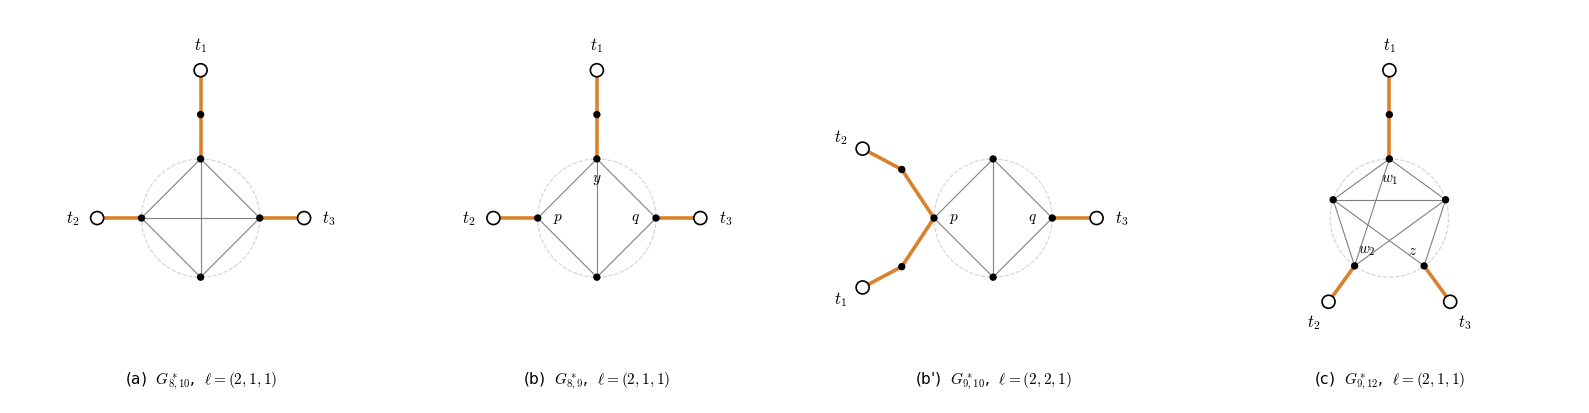

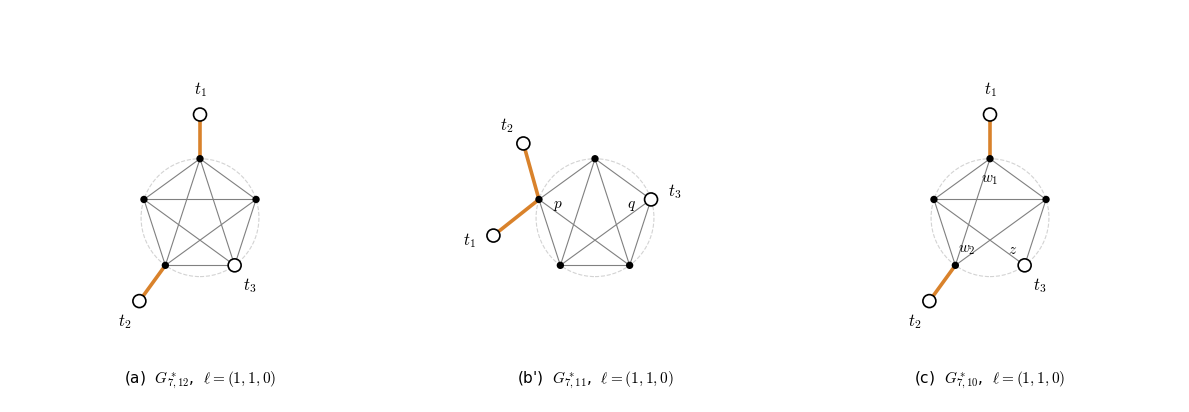

In [8]:
from math import cos, sin, pi

NARANJA = "#d9822b"


def patas_y_etiquetas(n, m):
    # nucleo B, patas [(u_r, l_r)] y etiquetas de vertices especiales, segun la Definicion del grafo modelo
    b = b_nm(n, m)
    np_, mp_ = n - b, m - b
    B, z, lam = globo(np_, mp_)
    l1, l2, l3 = terna_justa(b)
    c = caso(n, m)
    if c == "(a)":
        return B, [(0, l1), (1, l2), (2, l3)], {}
    p, q = z, np_ - 2
    if c == "(b)":
        return B, [(0, l1), (p, l2), (q, l3)], {0: "y", p: "p", q: "q"}
    if c == "(b')":
        return B, [(p, l1), (p, l2), (q, l3)], {p: "p", q: "q"}
    return B, [(lam, l1), (lam + 1, l2), (z, l3)], {lam: "w_1", lam + 1: "w_2", z: "z"}


def dibujar_modelo(n, m, titulo=None, R=1.0, paso=0.75):
    B, patas, etiq = patas_y_etiquetas(n, m)
    G, ts = theta(B, patas)
    np_ = B.order()

    # vertices del nucleo sobre un circulo; los enganches donde los pone la figura
    enganches = []
    for u, l in patas:
        if u not in enganches:
            enganches.append(u)
    deseados = {1: [90], 2: [180, 0], 3: [90, 210, 330]}[len(enganches)]
    libres_ang = [(90 + 360 * i / np_) % 360 for i in range(np_)]
    ang = {}
    for u, a in zip(enganches, deseados):
        mejor = min(libres_ang, key=lambda x: min(abs(x - a), 360 - abs(x - a)))
        ang[u] = mejor
        libres_ang.remove(mejor)
    for v in B.vertices(sort=True):
        if v not in ang:
            ang[v] = libres_ang.pop(0)
    pos = {v: (R * cos(float(a) * pi / 180), R * sin(float(a) * pi / 180)) for v, a in ang.items()}

    # patas: caminos hacia afuera en la direccion del enganche (abanico si comparten vertice)
    por_vertice = {}
    for r, (u, l) in enumerate(patas):
        por_vertice.setdefault(u, []).append(r)
    sig = np_
    etiquetas_t = {}
    for u, rs in por_vertice.items():
        desv = {1: [0], 2: [28, -28], 3: [30, 0, -30]}[len(rs)]
        for r, dv in zip(rs, desv):
            l = patas[r][1]
            a = (float(ang[u]) + dv) * pi / 180
            for k in range(1, l + 1):
                pos[sig] = ((R + paso * k) * cos(a), (R + paso * k) * sin(a))
                sig += 1
            etiquetas_t[ts[r]] = (r, a)

    g = circle((0, 0), R, color="lightgray", linestyle="--", thickness=0.8, zorder=0)
    puentes = set(map(frozenset, G.bridges(labels=False)))
    for u, v in G.edges(labels=False):
        if frozenset((u, v)) in puentes:
            g += line([pos[u], pos[v]], color=NARANJA, thickness=2.6, zorder=1)
        else:
            g += line([pos[u], pos[v]], color="gray", thickness=0.8, zorder=1)
    for v in G.vertices(sort=True):
        if v in ts:
            g += circle(pos[v], 0.11, fill=True, facecolor="white", edgecolor="black", thickness=1.2, zorder=5)
        else:
            g += point(pos[v], size=28, color="black", zorder=4)
    for v, s in etiq.items():
        x, y = pos[v]
        g += text(f"${s}$", (0.66 * x, 0.66 * y), fontsize=11, color="black", zorder=6)
    for t, (r, a) in etiquetas_t.items():
        x, y = pos[t]
        g += text(f"$t_{r + 1}$", (x + 0.42 * cos(a), y + 0.42 * sin(a)), fontsize=12, color="black", zorder=6)
    if titulo is None:
        titulo = f"{caso(n, m)}  $G^*_{{{n},{m}}}$,  $\\ell={terna_justa(b_nm(n, m))}$"
    g += text(titulo, (0, -R - 1.75), fontsize=11, color="black")
    g.set_axes_range(-3.1, 3.1, -3.0, 3.4)
    g.axes(False)
    g.set_aspect_ratio(1)
    return g


# Fila 1: los cuatro casos con b >= 3, como en la figura (ternas (2,1,1) y, en (b'), (2,2,1))
fila_b3 = [dibujar_modelo(n, m) for n, m in [(8, 10), (8, 9), (9, 10), (9, 12)]]
# Fila 2: los mismos casos con b = 2, terna (1,1,0): un terminal queda dentro del nucleo
fila_b2 = [dibujar_modelo(n, m) for n, m in [(7, 12), (7, 11), (7, 10)]]

for n, m in [(8, 10), (8, 9), (9, 10), (9, 12), (7, 12), (7, 11), (7, 10)]:
    G, ts = modelo(n, m)
    b = b_nm(n, m)
    print(f"{caso(n, m):4} G*_{{{n},{m}}}: b={b}, nucleo B_{{{n - b},{m - b}}}, l={terna_justa(b)}, F={F_tupla(G, ts)}")

graphics_array(fila_b3).show(figsize=[16, 4.6])
graphics_array(fila_b2).show(figsize=[12, 4.6])